# Visual phishing detection: an end-to-end ML pipeline

**African Leadership University · BSE · Machine Learning Pipeline summative**

My Intro to ML summative detected phishing from the **URL string** alone (PhiUSIIL, 235k URLs,
HistGradientBoosting vs a Keras MLP). Its main limitation was that URL features can be
learnt as collection artefacts rather than as real threat signals. This project tackles the same problem
from a different angle: **what the page looks like**. Phishing kits clone the look of the brand they
impersonate, so a screenshot of the page should reveal which brand is being targeted.

**Task:** given a screenshot of a web page, predict which of 14 heavily phished brands it imitates,
or `other` (a page that copies none of them, mostly legitimate sites).
This is a 15-class image classification problem.

**Data:** [Phish-IRIS](https://data.mendeley.com/datasets/tk4fkswtj5) (Dalgic, Bozkir & Aydos, 2018),
2,849 screenshots collected from PhishTank and OpenPhish between March and May 2018.

**Pipeline in this notebook**
1. Data acquisition
2. Data audit and cleaning (duplicates and leakage)
3. Preprocessing
4. Feature visualizations and interpretation
5. Model creation (MobileNetV2 transfer learning)
6. Training
7. Evaluation with all metrics
8. Prediction functions
9. Retraining

In [1]:
import json, sys, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src import preprocessing as pp
from src import model as M

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True})
BLUE, ORANGE = "#2a78d6", "#eb6834"
import tensorflow as tf
tf.keras.utils.set_random_seed(pp.SEED)
print("TensorFlow", tf.__version__)

I0000 00:00:1795428331.920452    4499 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795428331.952409    4499 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795428333.190342    4499 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Data acquisition

`src/preprocessing.py` downloads the archive (~800 MB) from Mendeley Data's public API,
extracts it and builds `data/train` and `data/test`. The processed data is already committed
to the repository (224×224 JPEGs, ~35 MB), so the download only runs if `REBUILD_DATA = True`.

In [2]:
REBUILD_DATA = False
RAW_DIR = None   # set to an extracted archive folder to skip the download

if REBUILD_DATA:
    audit = pp.prepare_dataset(Path(RAW_DIR)) if RAW_DIR else pp.acquire_and_prepare(ROOT / ".cache" / "phishiris")
    pp.save_statistics(pp.dataset_statistics())

audit = json.loads((ROOT / "reports" / "data_audit.json").read_text())
CLASS_NAMES = pp.get_class_names(pp.TRAIN_DIR)
print(len(CLASS_NAMES), "classes:", CLASS_NAMES)

15 classes: ['adobe', 'alibaba', 'amazon', 'apple', 'boa', 'chase', 'dhl', 'dropbox', 'facebook', 'linkedin', 'microsoft', 'other', 'paypal', 'wellsfargo', 'yahoo']


## 2. Data audit: duplicates and leakage

Before training, I hashed every file in the archive. The original release has two problems:

* **Exact duplicates.** Many screenshots appear two or three times, sometimes under the same name with
  `.png` and `.jpg` extensions.
* **Train/test leakage.** Many images in the official `val` folder are byte-identical copies of training
  images, so a model evaluated on that split is partly tested on data it has already seen.

The fix mirrors the hostname-disjoint split from my URL project:
1. keep one copy of every exact duplicate, and drop the one image that carried two different labels;
2. find **near-duplicates** (the same phishing kit captured twice) with a 64-bit difference hash, and join
   images whose hashes differ in 6 bits or fewer into one group;
3. pool everything and make a **stratified, group-disjoint** split of about 67% train and 33% test, so no
   near-copy of a test image is ever used for training.

In [3]:
summary = pd.Series({
    "files in archive": audit["files_total"],
    "exact duplicates inside a split": audit["duplicates_within_split"],
    "official test images also in train": audit["test_images_also_in_train"],
    "images with conflicting labels": audit["conflicting_label_hashes"],
    "unique images kept": audit["unique_images"],
    "near-duplicate groups": audit["near_duplicate_groups"],
    "images sharing a group": audit["images_in_multi_image_groups"],
    "train images": audit["n_train"],
    "test images": audit["n_test"],
}, name="count")
summary.to_frame()

,count
files in archive,2849
exact duplicates inside a split,196
official test images also in train,204
images with conflicting labels,1
unique images kept,2448
near-duplicate groups,2221
images sharing a group,342
train images,1632
test images,816


## 3. Preprocessing

Each screenshot goes through `pp.load_image`:

1. **Decode** PNG/JPEG/BMP/WebP, and apply EXIF orientation.
2. **Flatten transparency.** About a quarter of the PNGs are RGBA. Transparent pixels are composited onto
   white, which is how a browser shows them. Dropping the alpha channel instead would turn them black.
3. **Convert to RGB** and **resize to 224×224** (bilinear), the MobileNetV2 input size. Screenshots are
   close to square (median about 1024×1012), so resizing barely distorts them.
4. **Scale pixels to [-1, 1].** This is a `Rescaling` layer inside the model, so the API, the notebook and
   retraining all send the same raw 0–255 pixels.

During training only, mild **augmentation** is applied: random translation (±5%), zoom (±10%) and contrast
(±10%). There are deliberately no flips or rotations, because real screenshots are never mirrored and a
mirrored logo is not a real logo. Class imbalance is handled with softened (inverse square root) class
weights.

In [4]:
counts = pd.DataFrame({"train": audit["train"], "test": audit["test"]}).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
counts.index = [pp.CLASS_LABELS[c] for c in counts.index]
counts

,train,test,total
Other / legitimate,914,456,1370
PayPal,117,58,175
Facebook,74,36,110
Microsoft,61,30,91
Wells Fargo,59,30,89
Chase,56,28,84
Bank of America,54,27,81
Dropbox,53,27,80
DHL,52,26,78
Yahoo,51,26,77


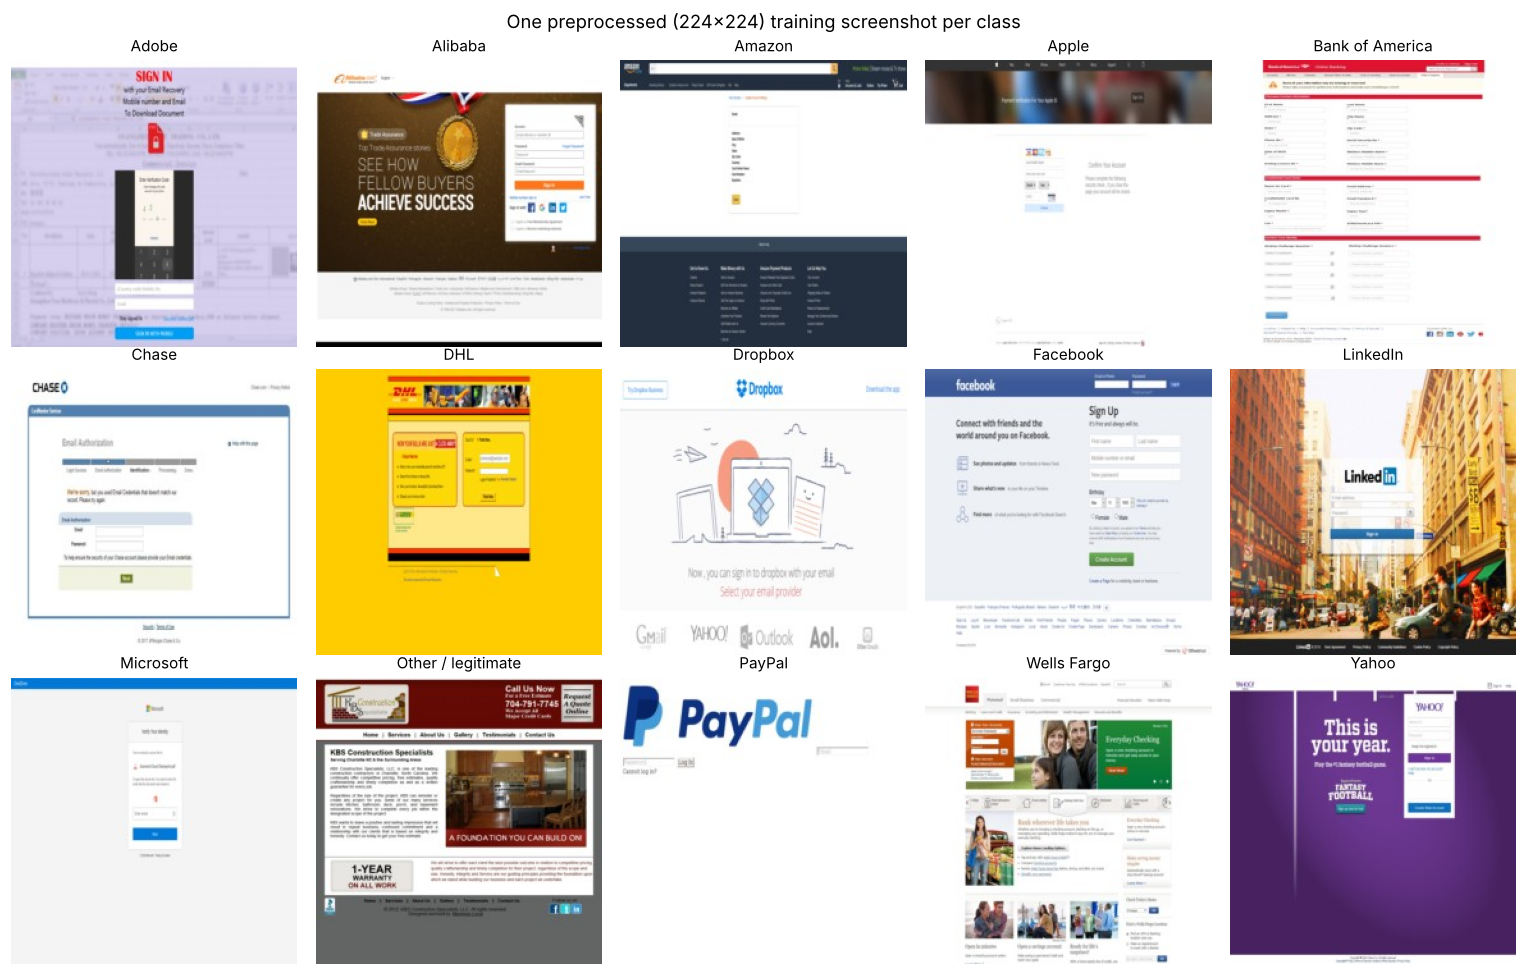

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for ax, c in zip(axes.flat, CLASS_NAMES):
    f = pp.list_images(pp.TRAIN_DIR / c)[0]
    ax.imshow(Image.open(f)); ax.set_title(pp.CLASS_LABELS[c], fontsize=10); ax.axis("off")
fig.suptitle("One preprocessed (224×224) training screenshot per class")
fig.tight_layout(); fig.savefig(FIG / "samples.png", bbox_inches="tight"); plt.show()

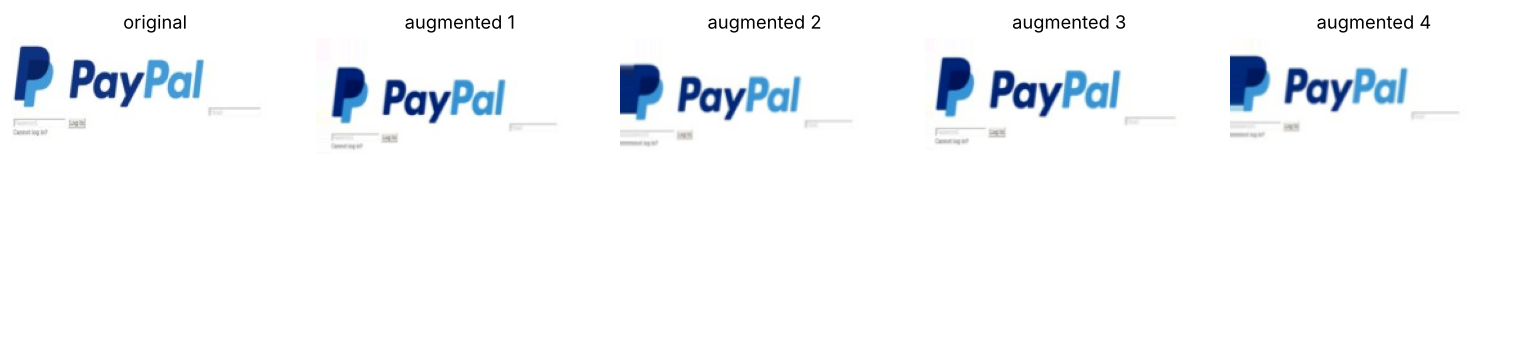

In [6]:
# What augmentation does to one image (training only)
model_tmp = M.build_model(len(CLASS_NAMES))
aug = model_tmp.get_layer("augmentation")
img = pp.image_to_array(pp.load_image(pp.list_images(pp.TRAIN_DIR / "paypal")[0]))[None]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(img[0].astype("uint8")); axes[0].set_title("original")
for i, ax in enumerate(axes[1:], 1):
    ax.imshow(np.clip(aug(img, training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title(f"augmented {i}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
del model_tmp

## 4. Feature visualizations and interpretation

Screenshots have no columns, so I extracted interpretable **visual features** from each image
(`pp.image_features`). The four used below are:

| feature | meaning |
|---|---|
| class label | which brand is imitated (the target) |
| mean R/G/B, saturation | the colour palette of the page |
| edge density | share of pixels on an edge, a proxy for visual clutter (text, images, menus) |
| whitespace ratio | share of near-white pixels, typical of bare login forms |

In [7]:
rows = []
for split, folder in (("train", pp.TRAIN_DIR), ("test", pp.TEST_DIR)):
    for c in CLASS_NAMES:
        for f in pp.list_images(folder / c):
            rows.append({"split": split, "label": c, "brand": pp.CLASS_LABELS[c], **pp.image_features(f)})
feats = pd.DataFrame(rows)
feats["blue_minus_red"] = feats["mean_b"] - feats["mean_r"]
feats["is_phish"] = np.where(feats["label"] == "other", "other / legitimate", "brand (phishing)")
feats.groupby("brand")[["brightness", "saturation", "blue_minus_red", "edge_density", "whitespace_ratio"]].mean().round(3)

,brightness,saturation,blue_minus_red,edge_density,whitespace_ratio
brand,,,,,
Adobe,187.265,24.228,-11.983,0.088,0.484
Alibaba,225.494,27.184,-3.892,0.095,0.721
Amazon,224.734,13.554,-3.553,0.081,0.730
Apple,203.999,23.385,-0.939,0.089,0.664
Bank of America,232.209,17.655,-8.040,0.125,0.741
Chase,217.524,25.873,0.396,0.143,0.671
DHL,190.906,94.339,-81.174,0.117,0.427
Dropbox,239.297,9.952,2.221,0.085,0.827
Facebook,215.200,33.628,17.542,0.080,0.618


### Feature 1: class balance (which brands get phished most)

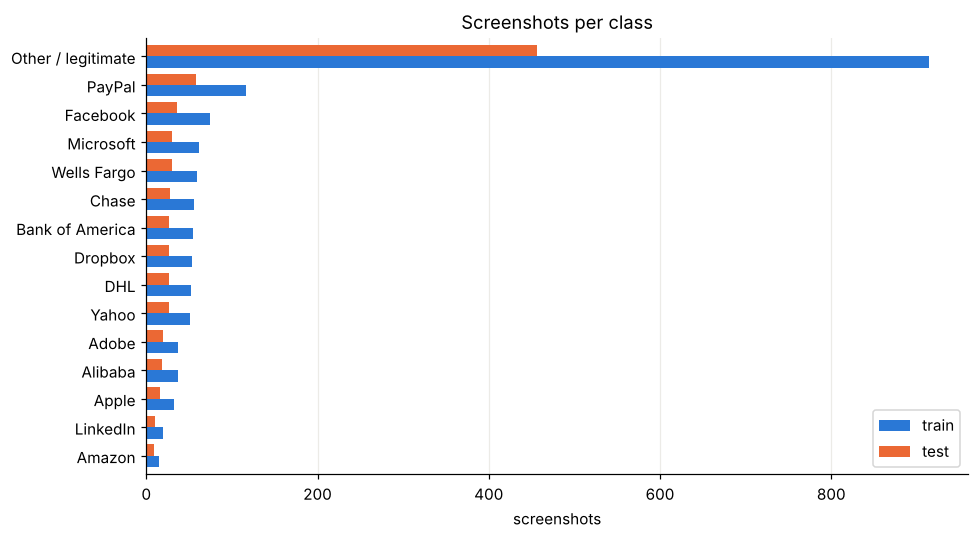

'other' share: 56.0%


In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
counts[["train", "test"]].iloc[::-1].plot.barh(ax=ax, color=[BLUE, ORANGE], width=0.8)
ax.set_xlabel("screenshots"); ax.set_title("Screenshots per class"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "class_balance.png"); plt.show()
share_other = counts.loc["Other / legitimate", "total"] / counts["total"].sum()
print(f"'other' share: {share_other:.1%}")

**Interpretation.** The data is heavily imbalanced. `other` makes up over half of all images, and among the
brands PayPal and Facebook dominate while Amazon and LinkedIn have only a few dozen examples. That matches
the real phishing landscape: attackers go after payment and social login credentials first. For modelling,
it means accuracy alone would flatter a model that leans towards `other`. So I use class weights in
training and report **macro-F1** and **balanced accuracy**, which give each brand equal weight.

### Feature 2: colour (phishing kits copy the brand palette)

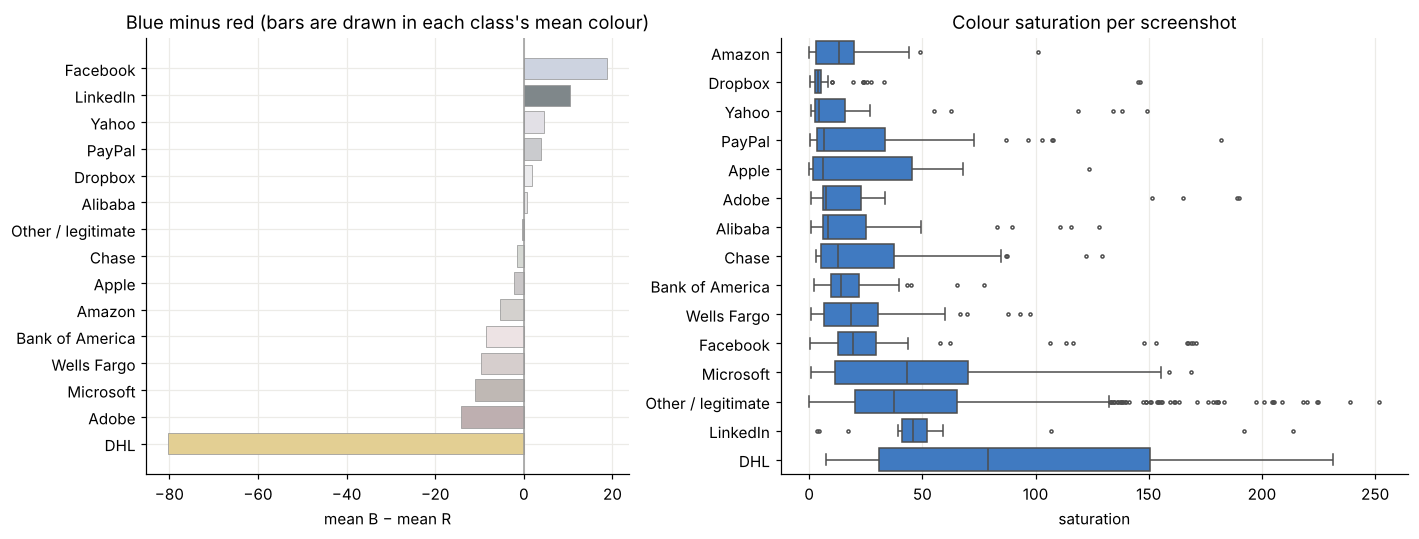

In [9]:
col = feats[feats.split == "train"].groupby("brand")[["mean_r", "mean_g", "mean_b", "saturation", "blue_minus_red"]].mean()
col = col.sort_values("blue_minus_red")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh(col.index, col["blue_minus_red"], color=[tuple(v / 255) for v in col[["mean_r", "mean_g", "mean_b"]].values],
             edgecolor="#999", linewidth=0.5)
axes[0].axvline(0, color="#999", lw=1)
axes[0].set_title("Blue minus red (bars are drawn in each class's mean colour)"); axes[0].set_xlabel("mean B − mean R")
order = feats.groupby("brand")["saturation"].median().sort_values().index
sns.boxplot(data=feats[feats.split == "train"], y="brand", x="saturation", order=order, ax=axes[1],
            color=BLUE, fliersize=2, linewidth=1)
axes[1].set_title("Colour saturation per screenshot"); axes[1].set_ylabel("")
fig.tight_layout(); fig.savefig(FIG / "colour.png"); plt.show()

**Interpretation.** Colour carries real brand signal. DHL pages stand out with a strong yellow/red cast
(blue − red ≈ −80, the highest saturation), while Facebook and LinkedIn lean blue and Adobe and Microsoft
lean red/orange. Dropbox, Yahoo and Alibaba pages are almost colourless, essentially a white form. So colour
alone can separate a few brands, but the many white-and-blue login pages (PayPal, Chase, Bank of America,
Dropbox) look alike in colour. Separating them needs the **logo and layout**, which is why a CNN is used
rather than colour histograms.

### Feature 3: layout (clutter and whitespace)

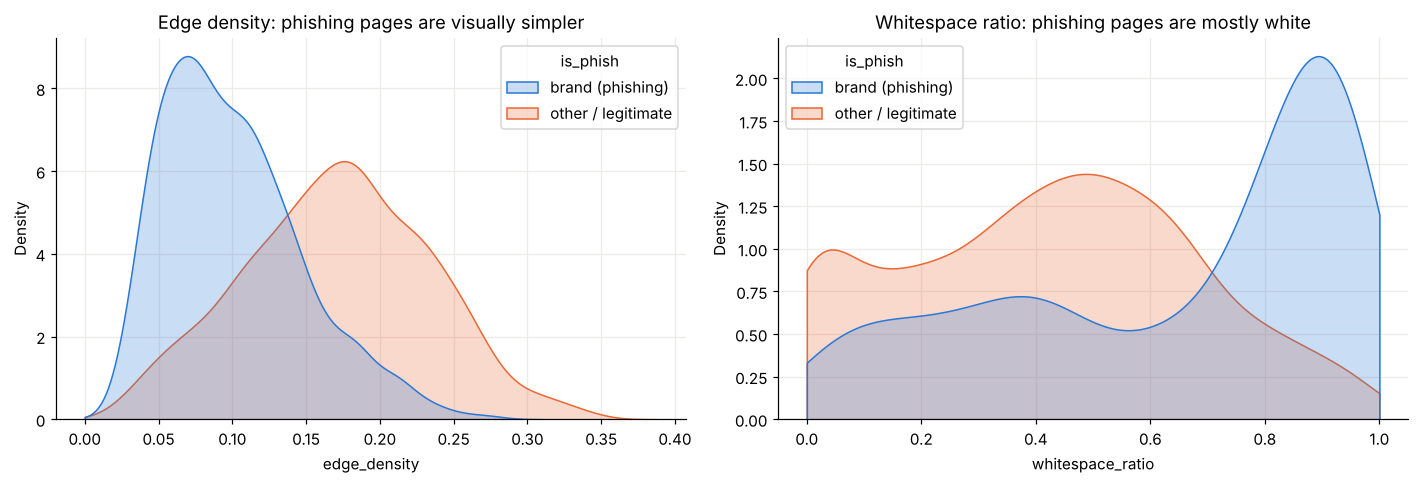

,edge_density,whitespace_ratio,brightness
is_phish,,,
brand (phishing),0.093,0.777,233.063
other / legitimate,0.172,0.431,188.378


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.kdeplot(data=feats, x="edge_density", hue="is_phish", ax=axes[0], fill=True, common_norm=False,
            palette=[BLUE, ORANGE], clip=(0, 0.5))
axes[0].set_title("Edge density: phishing pages are visually simpler")
sns.kdeplot(data=feats, x="whitespace_ratio", hue="is_phish", ax=axes[1], fill=True, common_norm=False,
            palette=[BLUE, ORANGE], clip=(0, 1))
axes[1].set_title("Whitespace ratio: phishing pages are mostly white")
fig.tight_layout(); fig.savefig(FIG / "layout.png"); plt.show()
feats.groupby("is_phish")[["edge_density", "whitespace_ratio", "brightness"]].median().round(3)

**Interpretation.** Legitimate (`other`) pages are real websites with menus, photos and long text, so their
edge density is about twice that of phishing pages, and less than half of their pixels are white.
Phishing pages are mostly **sparse login forms on a white background**: a logo, two input boxes and a
button. LinkedIn is the exception among brands, with dark, cluttered pages. Put together:
*a sparse, bright page showing a famous brand's colours and logo, but not hosted by that brand, is the
visual signature of a phishing kit.* These differences also suggest that part of what a model learns is
"login page vs. content page". That is a useful signal, but it means a legitimate login page could be
flagged. I come back to this in the evaluation.

## 5. Model creation

**Architecture:** MobileNetV2 pretrained on ImageNet, with a new head
(global average pooling → dropout 0.3 → dense softmax over 15 classes with L2 regularisation).

Why MobileNetV2: with only about 1,600 training images, training from scratch would overfit, so transfer
learning is the right tool. MobileNetV2 is small (about 9 MB, 2.3M parameters) and fast on a CPU, which
matters for a cloud API that has to handle a flood of requests and retrain on the server.

**Training strategy**
1. *Feature extraction:* freeze the backbone, train only the head (Adam, lr 1e-3, up to 25 epochs).
2. *Fine-tuning:* unfreeze the top 50 backbone layers, keeping BatchNorm frozen, and continue at lr 2e-5
   (up to 15 epochs).

Both phases use early stopping on validation loss (patience 5, best weights restored) and
ReduceLROnPlateau. The validation set is a stratified 15% of the training folder. The test set is
never used for training or model selection.

In [11]:
m = M.build_model(len(CLASS_NAMES))
m.summary(line_length=100)
paths, labels = pp.collect_files([pp.TRAIN_DIR], CLASS_NAMES)
cw = M.class_weights(labels, len(CLASS_NAMES))
pd.Series({pp.CLASS_LABELS[c]: round(cw[i], 2) for i, c in enumerate(CLASS_NAMES)}, name="class weight").to_frame().T

Model: "phish_iris_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                         │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ augmentation (Sequential)                  │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ mobilenet_scaling (Rescaling)              │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ mobilenetv2_1.00_224 (Functional)          │ (None, 7, 7, 1280)              │         2,257,984 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ global_average_pooling2d_1                 │ (None, 1280)                    │                 0 │
│ (GlobalAveragePooling2D)                   │                                 │                   │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dropout_1 (Dropout)                        │ (None, 1280)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ brand (Dense)                              │ (None, 15)                      │            19,215 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

,Adobe,Alibaba,Amazon,Apple,Bank of America,Chase,DHL,Dropbox,Facebook,LinkedIn,Microsoft,Other / legitimate,PayPal,Wells Fargo,Yahoo
class weight,2.1,2.1,3.3,2.26,1.74,1.71,1.77,1.75,1.48,2.86,1.64,0.42,1.18,1.66,1.79


## 6. Training

To show what fine-tuning adds, I train two models with the same data and seed:
* **Model A:** frozen backbone, head only;
* **Model B:** Model A, then fine-tuned. This is the model that gets deployed.

(Model A's metrics are recorded before fine-tuning starts. Fine-tuning then continues on the same weights.)

In [12]:
t0 = time.time()
model_a, hist_a, _ = M.train(head_epochs=25, finetune_epochs=0, verbose=0)
time_a = time.time() - t0
metrics_a = M.evaluate(model_a, CLASS_NAMES)
print(f"Model A trained in {time_a:.0f}s: test accuracy {metrics_a['accuracy']:.3f}, macro-F1 {metrics_a['macro_f1']:.3f}")

Model A trained in 372s: test accuracy 0.759, macro-F1 0.579


In [13]:
t0 = time.time()
model_b, hist_b, _ = M.train(model=model_a, class_names=CLASS_NAMES, finetune_epochs=15, verbose=0)
time_b = time.time() - t0 + time_a
for k in ("loss", "val_loss", "accuracy", "val_accuracy"):
    hist_b[k] = hist_a[k] + hist_b[k]
hist_b["phase"] = hist_a["phase"] + hist_b["phase"]
metrics_b = M.evaluate(model_b, CLASS_NAMES)
print(f"Model B trained in {time_b:.0f}s total: test accuracy {metrics_b['accuracy']:.3f}, macro-F1 {metrics_b['macro_f1']:.3f}")

Model B trained in 635s total: test accuracy 0.788, macro-F1 0.649


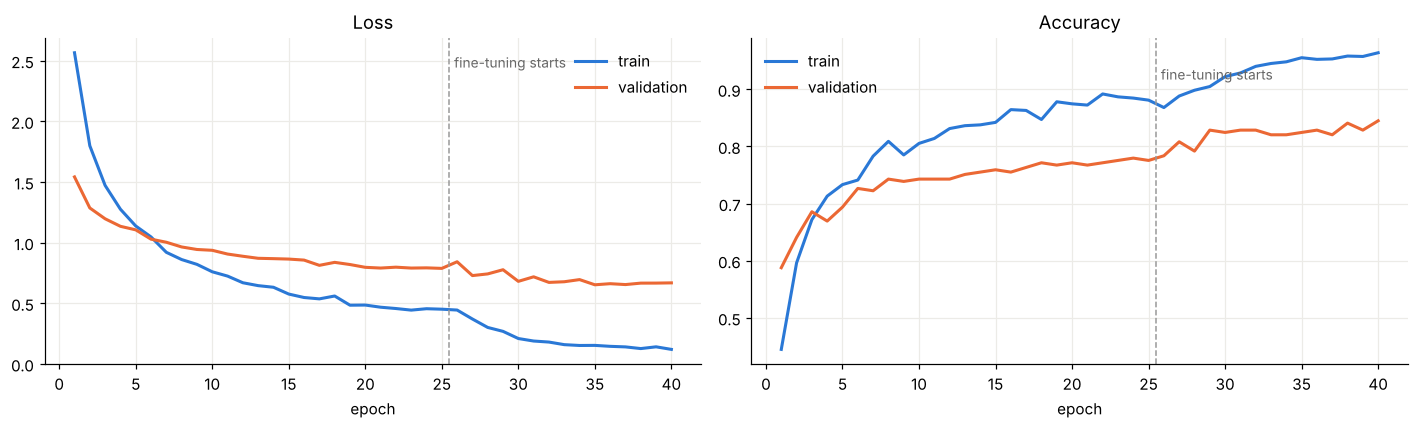

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
n_head = hist_b["phase"].count("head")
for ax, k, title in ((axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")):
    ep = np.arange(1, len(hist_b[k]) + 1)
    ax.plot(ep, hist_b[k], color=BLUE, lw=2, label="train")
    ax.plot(ep, hist_b["val_" + k], color=ORANGE, lw=2, label="validation")
    ax.axvline(n_head + 0.5, color="#999", ls="--", lw=1)
    ax.text(n_head + 0.8, ax.get_ylim()[1] * 0.95, "fine-tuning starts", color="#666", fontsize=9, va="top")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "learning_curves.png"); plt.show()

## 7. Evaluation

All metrics are computed on the untouched, group-disjoint test set (`M.evaluate`):

* **Accuracy** and **balanced accuracy** (mean per-class recall);
* **Top-3 accuracy**: is the right brand among the three best guesses;
* **Precision, recall, F1**, macro-averaged (each class counts equally) and weighted;
* **Cohen's kappa**: agreement beyond chance;
* **Log loss**: quality of the probabilities;
* **Per-class report** and **confusion matrix**;
* a **binary view**, phishing (any brand) vs. `other`, with ROC-AUC and average precision on the
  phishing score 1 − P(other). This is the security question the model answers in practice.

In [15]:
keys = ["accuracy", "balanced_accuracy", "top3_accuracy", "macro_precision", "macro_recall", "macro_f1",
        "weighted_precision", "weighted_recall", "weighted_f1", "cohen_kappa", "log_loss"]
comp = pd.DataFrame({"A: frozen backbone": [metrics_a[k] for k in keys],
                     "B: fine-tuned (deployed)": [metrics_b[k] for k in keys]}, index=keys)
bk = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
binary = pd.DataFrame({"A: frozen backbone": [metrics_a["binary_phishing_vs_legit"][k] for k in bk],
                       "B: fine-tuned (deployed)": [metrics_b["binary_phishing_vs_legit"][k] for k in bk]},
                      index=["binary_" + k for k in bk])
pd.concat([comp, binary]).round(4)

,A: frozen backbone,B: fine-tuned (deployed)
accuracy,0.7586,0.7880
balanced_accuracy,0.5501,0.6129
top3_accuracy,0.9081,0.9265
macro_precision,0.7006,0.7279
macro_recall,0.5501,0.6129
macro_f1,0.5793,0.6490
weighted_precision,0.7580,0.7857
weighted_recall,0.7586,0.7880
weighted_f1,0.7429,0.7791
cohen_kappa,0.6211,0.6705


In [16]:
rep = pd.DataFrame(metrics_b["per_class"]).T.loc[CLASS_NAMES]
rep.index = [pp.CLASS_LABELS[c] for c in rep.index]
rep[["precision", "recall", "f1-score", "support"]].round(3).sort_values("f1-score")

,precision,recall,f1-score,support
LinkedIn,0.667,0.200,0.308,10.0
Microsoft,0.600,0.400,0.480,30.0
Apple,0.700,0.438,0.538,16.0
Yahoo,0.619,0.500,0.553,26.0
Wells Fargo,0.593,0.533,0.561,30.0
Facebook,0.622,0.639,0.630,36.0
PayPal,0.650,0.672,0.661,58.0
Alibaba,1.000,0.500,0.667,18.0
Amazon,0.667,0.667,0.667,9.0
Dropbox,0.647,0.815,0.721,27.0


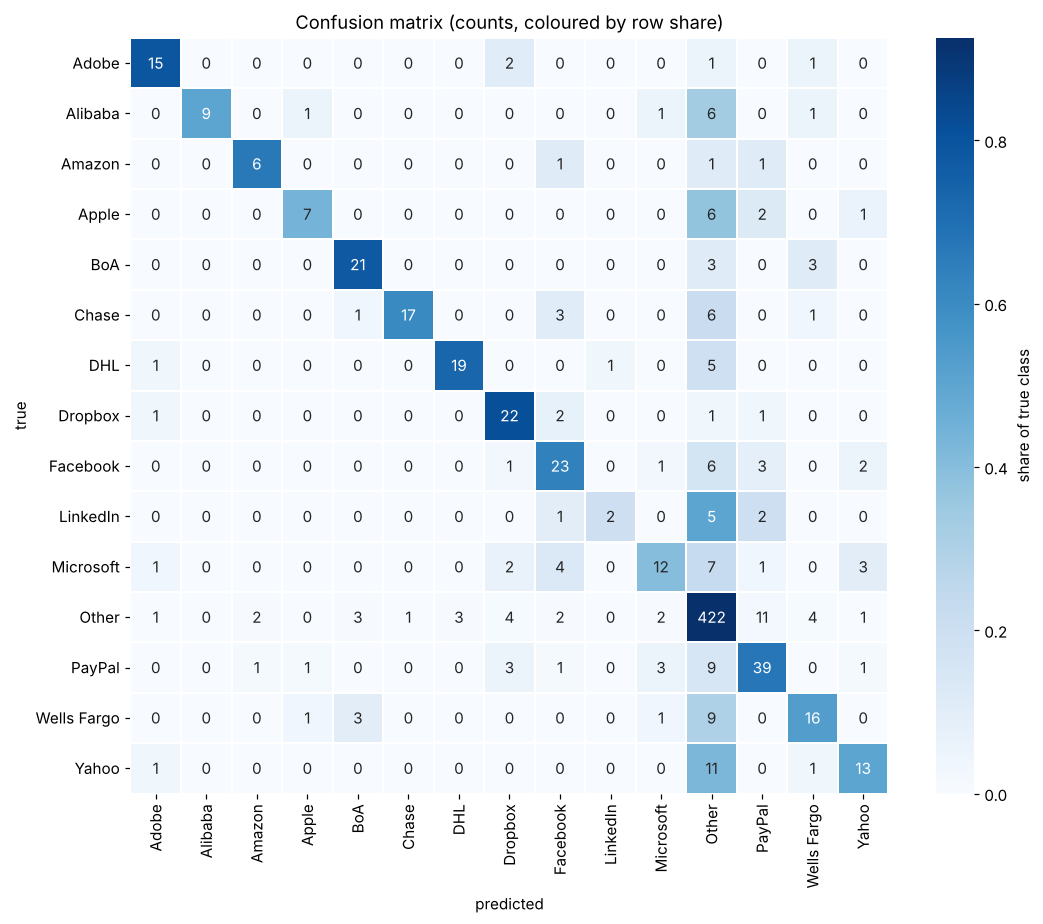

In [17]:
cm = np.array(metrics_b["confusion_matrix"])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
short = [pp.CLASS_LABELS[c].replace("Other / legitimate", "Other").replace("Bank of America", "BoA") for c in CLASS_NAMES]
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", xticklabels=short, yticklabels=short, ax=ax,
            cbar_kws={"label": "share of true class"}, linewidths=1, linecolor="white")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (counts, coloured by row share)")
fig.tight_layout(); fig.savefig(FIG / "confusion_matrix.png"); plt.show()

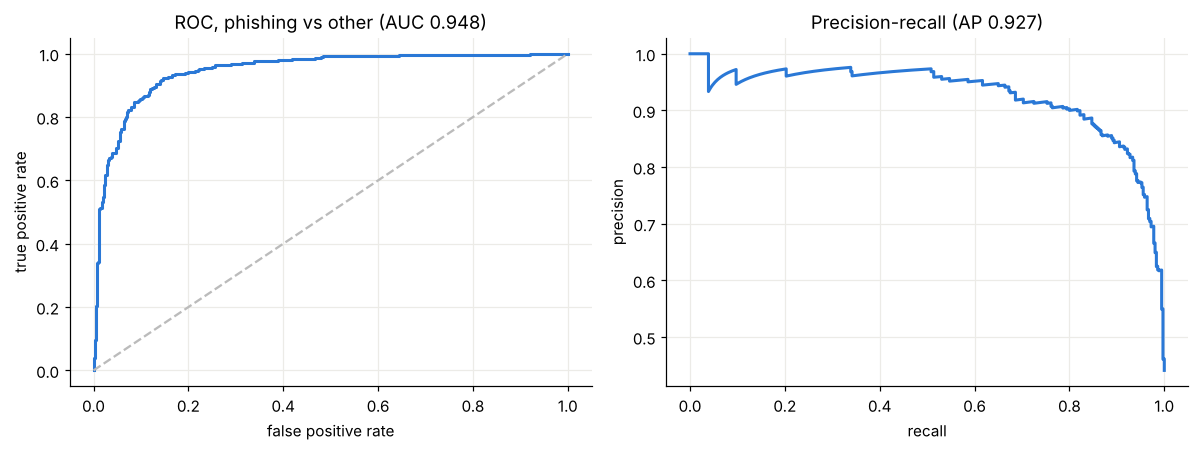

In [18]:
from sklearn.metrics import roc_curve, precision_recall_curve
y, probs, test_paths = M.predict_dir(model_b, pp.TEST_DIR, CLASS_NAMES)
other = CLASS_NAMES.index("other")
yb, score = (y != other).astype(int), 1 - probs[:, other]
fpr, tpr, _ = roc_curve(yb, score); prec, rec, _ = precision_recall_curve(yb, score)
b = metrics_b["binary_phishing_vs_legit"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(fpr, tpr, color=BLUE, lw=2); axes[0].plot([0, 1], [0, 1], color="#bbb", ls="--")
axes[0].set(title=f"ROC, phishing vs other (AUC {b['roc_auc']:.3f})", xlabel="false positive rate", ylabel="true positive rate")
axes[1].plot(rec, prec, color=BLUE, lw=2)
axes[1].set(title=f"Precision-recall (AP {b['average_precision']:.3f})", xlabel="recall", ylabel="precision")
fig.tight_layout(); fig.savefig(FIG / "roc_pr.png"); plt.show()

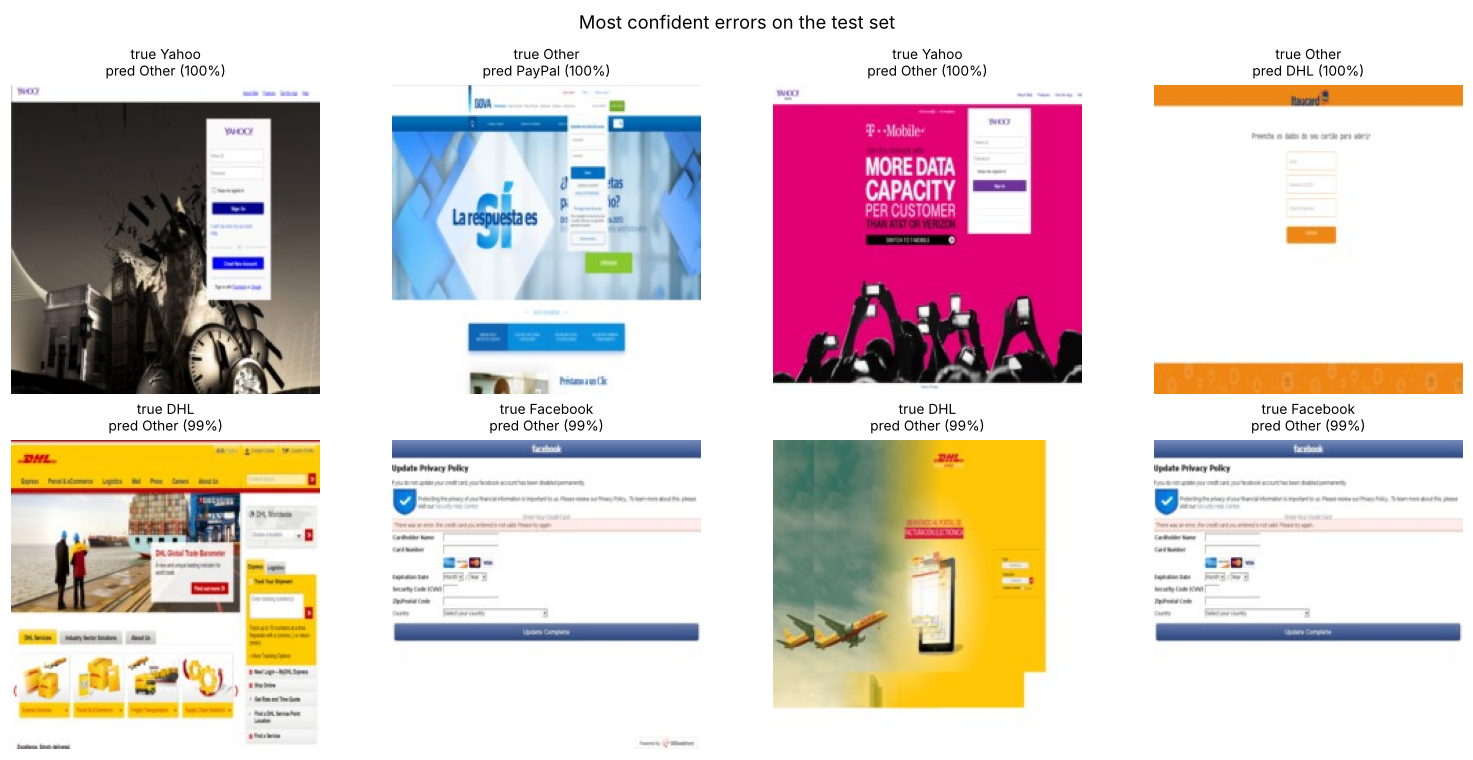

In [19]:
# Where does the model go wrong? The most confident mistakes.
pred = probs.argmax(1)
wrong = np.where(pred != y)[0]
worst = wrong[np.argsort(-probs[wrong, pred[wrong]])][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, worst):
    ax.imshow(Image.open(test_paths[i])); ax.axis("off")
    ax.set_title(f"true {short[y[i]]}\npred {short[pred[i]]} ({probs[i, pred[i]]:.0%})", fontsize=9)
fig.suptitle("Most confident errors on the test set"); fig.tight_layout(); plt.show()

### What the results say

| | Model A (frozen) | **Model B (fine-tuned, deployed)** |
|---|---|---|
| accuracy | 0.759 | **0.788** |
| balanced accuracy | 0.550 | **0.613** |
| top-3 accuracy | 0.908 | **0.927** |
| macro F1 | 0.579 | **0.649** |
| Cohen's kappa | 0.621 | **0.671** |
| phishing vs. other, F1 | 0.823 | **0.838** |
| phishing vs. other, ROC-AUC | 0.936 | **0.948** |

* **Fine-tuning helps on every metric.** Macro-F1 rises by 7 points, and it helps the rare brands most.
* **As a phishing detector, the model is strong.** ROC-AUC is 0.95 and precision is 0.89: when it says a page imitates a brand,
  it is right about 9 times in 10. Recall is 0.79, so about 1 phishing page in 5 is mistaken for `other`.
* **As a brand identifier, it is good but uneven.** The right brand is in the top 3 for 93% of pages. DHL, Adobe, Bank of
  America and Chase (distinctive colours and logos) score F1 0.74–0.79. LinkedIn (10 test images), Microsoft and Apple are
  the weakest. Their kits vary a lot, and Microsoft/Office 365 pages are often plain white forms with a small logo,
  which is hard to read at 224×224.
* **Most errors are brand → `other`**, not one brand mistaken for another (see the confusion matrix). In a security tool,
  that means the model fails safe: it misses some phishing pages, rather than raising false alarms.
* **Train accuracy (~96%) is well above validation accuracy (~82%)**, so the model still overfits a little despite augmentation,
  dropout, L2 and early stopping. More data per brand is the clearest way to improve it, and that is exactly what the
  upload-and-retrain loop is for.
* These scores are lower than the ~90% often reported on Phish-IRIS. Part of the gap is deliberate: duplicates and
  near-duplicates were removed from the test set, so the model cannot score by memorising.

## 8. Prediction functions

`src/prediction.py` wraps the saved model in a `Predictor`. It accepts raw bytes, a file path or a PIL
image, runs the same preprocessing, and returns the brand, the confidence, the top-3 classes and a phishing
score. The API calls exactly this function.

First we save Model B as the production model, version 1 in `models/registry.json`.

In [20]:
import shutil
for p in (M.MODEL_PATH, M.REGISTRY_PATH, M.VERSIONS_DIR):
    if p.is_dir(): shutil.rmtree(p)
    elif p.exists(): p.unlink()
entry = M.save_model(model_b, CLASS_NAMES, hist_b, metrics_b, trigger="initial (notebook)")
entry

{'version': 1,
 'file': 'models/versions/phish_iris_mobilenetv2_v1.h5',
 'created_at': '2026-11-23T10:16:44+00:00',
 'trigger': 'initial (notebook)',
 'new_images': 0,
 'n_train': 1387,
 'accuracy': 0.7879901960784313,
 'macro_f1': 0.648993855971497,
 'binary_f1': 0.8377581120943953,
 'promoted': True}

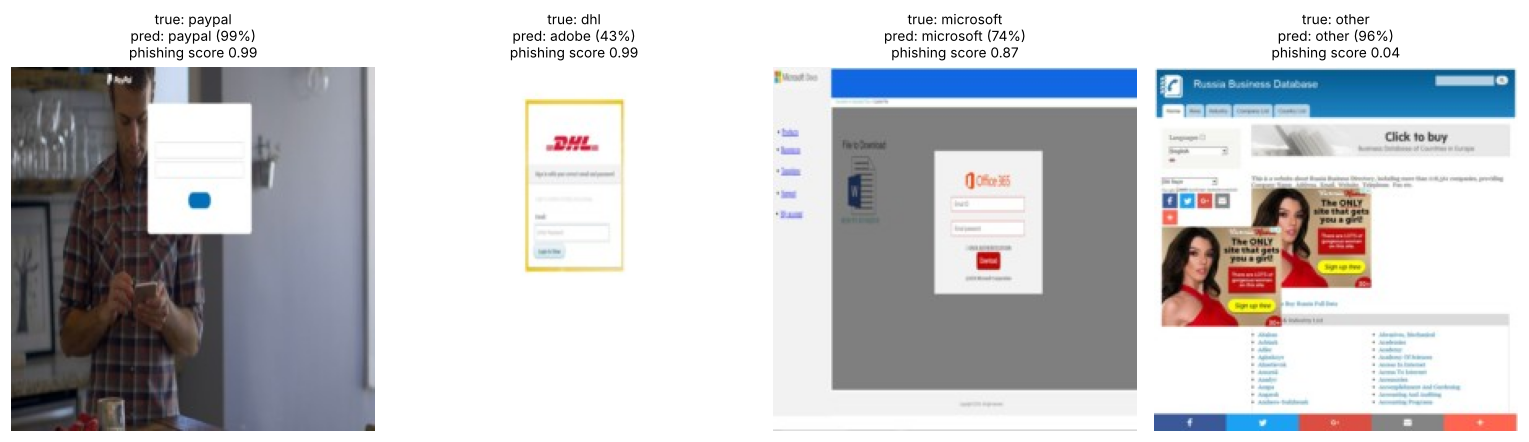

{'label': 'paypal',
 'brand': 'PayPal',
 'confidence': 0.9876,
 'verdict': 'possible phishing page imitating PayPal',
 'phishing_score': 0.9892,
 'top_k': [{'label': 'paypal', 'brand': 'PayPal', 'probability': 0.9876},
  {'label': 'other', 'brand': 'Other / legitimate', 'probability': 0.0108},
  {'label': 'chase', 'brand': 'Chase', 'probability': 0.0014}],
 'model_version': 1}

In [21]:
from src.prediction import Predictor
predictor = Predictor()
rng = np.random.default_rng(1)
picks = [pp.list_images(pp.TEST_DIR / c)[0] for c in ("paypal", "dhl", "microsoft", "other")]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, f in zip(axes, picks):
    r = predictor.predict(f)
    ax.imshow(Image.open(f)); ax.axis("off")
    ax.set_title(f"true: {f.parent.name}\npred: {r['label']} ({r['confidence']:.0%})\nphishing score {r['phishing_score']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()
predictor.predict(picks[0])

In [22]:
# Latency of a single prediction (what the API pays per request)
img_bytes = picks[0].read_bytes()
times = []
for _ in range(30):
    t = time.perf_counter(); predictor.predict(img_bytes); times.append((time.perf_counter() - t) * 1000)
print(f"single-image prediction: median {np.median(times):.1f} ms, p95 {np.percentile(times, 95):.1f} ms")

single-image prediction: median 150.5 ms, p95 170.9 ms


## 9. Retraining

Retraining is built into `src/model.py` and exposed by the API and the UI:

1. Users upload labelled screenshots (many images with one label, or a `.zip` with one folder per
   class). They land in `data/uploads/<class>/`.
2. **Triggers:** the *Retrain* button (`POST /retrain`), or automatically once
   `RETRAIN_THRESHOLD` (default 30) uploaded images are waiting.
3. `M.retrain()` warm-starts from the production model and fine-tunes on `data/train` + uploads.
4. It evaluates the candidate on the same test set and **promotes it only if macro-F1 does not drop by more than
   0.01**. Every candidate is stored in `models/versions/` and logged in `models/registry.json`.
5. The uploads are moved into `data/train`, and every API container hot-reloads the new model.

The cell below shows a real retrain: it uploads 30 screenshots and runs the same function the API runs.
To keep the test set clean, the "new" images are augmented copies of training images (shifted and
re-compressed), not test images.

In [23]:
RUN_RETRAIN_DEMO = True
if RUN_RETRAIN_DEMO:
    rng = np.random.default_rng(7)
    for c in ("amazon", "linkedin", "apple"):
        out = pp.UPLOAD_DIR / c; out.mkdir(parents=True, exist_ok=True)
        for i, f in enumerate(pp.list_images(pp.TRAIN_DIR / c)[:10]):
            im = Image.open(f); dx, dy = rng.integers(-8, 9, 2)
            im = im.transform(im.size, Image.AFFINE, (1, 0, dx, 0, 1, dy), fillcolor=(255, 255, 255))
            im.save(out / f"demo_upload_{i}.jpg", quality=80)
    print("pending uploads:", M.pending_uploads())
    t0 = time.time()
    result = M.retrain(trigger="notebook demo", epochs=3)
    print(f"retrain finished in {time.time() - t0:.0f}s")
    display(pd.DataFrame(M.load_registry()["versions"]).drop(columns=["file"]))
    # The demo images were moved into data/train by retrain(); remove them so the
    # committed training data stays the same as the audited split.
    for f in pp.TRAIN_DIR.rglob("demo_upload_*.jpg"):
        f.unlink()

pending uploads: {'amazon': 10, 'apple': 10, 'linkedin': 10}
Retraining with 30 new images: {'amazon': 10, 'apple': 10, 'linkedin': 10}


Candidate v2: macro-F1 0.5923 (current 0.6490) -> rejected
retrain finished in 63s


,version,created_at,trigger,new_images,n_train,accuracy,macro_f1,binary_f1,promoted
0,1,2026-11-23T10:16:44+00:00,initial (notebook),0,1387,0.787990,0.648994,0.837758,True
1,2,2026-11-23T10:17:53+00:00,notebook demo,30,1412,0.768382,0.592311,0.834302,False


In this run the candidate (v2) scored macro-F1 0.592, against 0.649 for the production model. It was more than 0.01 worse, so it was **rejected**. The production model stays at v1, and v2 is kept in `models/versions/` for inspection. This is the safeguard working as intended: fine-tuning on a small, skewed batch of uploads (only Amazon, Apple and LinkedIn) can make the model forget other classes, and the promotion check stops such a model from reaching users.

## Conclusion

* The pipeline goes from the raw archive to a deployed, retrainable model. The audit found that **400 of the
  2,849 files were exact duplicates, and 204 official test images were copies of training images**.
  Fixing that, and splitting by near-duplicate group, gives honest test scores.
* The fine-tuned MobileNetV2 is the deployed model. The metrics above compare it with the frozen baseline.
* The visual features show why the task is learnable: phishing kits copy brand colours and are sparse white
  login forms. They also show a risk: part of the signal is "login page vs. content page", so a legitimate
  login page could look suspicious. As in my URL project, the next step is testing on newer screenshots
  collected independently (Phish-IRIS dates from 2018).